SOLAR POWER OPTIMIZATION RESULTS
Optimal Voltage: 30.39 V
Maximum Power: 229.64 W


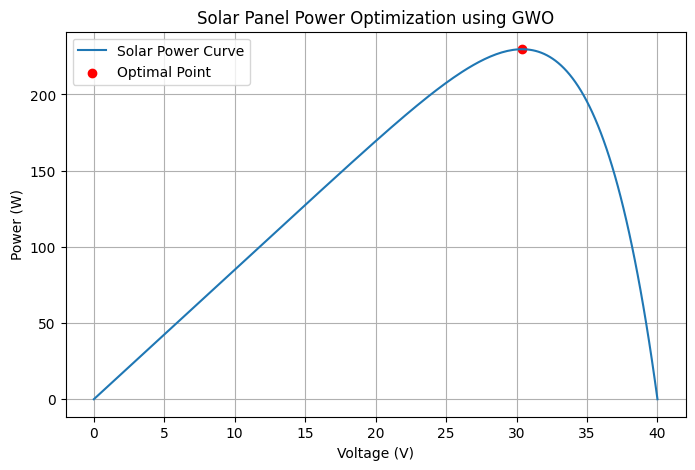

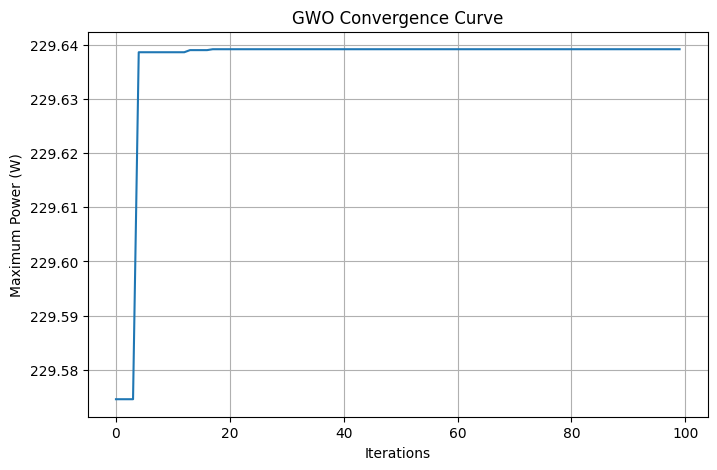

In [1]:

import numpy as np
import matplotlib.pyplot as plt

N = 20
MaxIter = 100

LB = 0
UB = 40

Isc = 8.5
Voc = 40
exponent = 8

def solar_power(V):
    I = Isc * (1 - (V / Voc) ** exponent)
    I = max(0, I)
    P = V * I
    return P

wolves = np.random.uniform(LB, UB, N)

alpha_pos = 0
beta_pos = 0
delta_pos = 0

alpha_score = -float("inf")
beta_score = -float("inf")
delta_score = -float("inf")

convergence = []

for iteration in range(MaxIter):

    for i in range(N):

        score = solar_power(wolves[i])

        if score > alpha_score:
            delta_score = beta_score
            delta_pos = beta_pos

            beta_score = alpha_score
            beta_pos = alpha_pos

            alpha_score = score
            alpha_pos = wolves[i]

        elif score > beta_score:
            delta_score = beta_score
            delta_pos = beta_pos

            beta_score = score
            beta_pos = wolves[i]

        elif score > delta_score:
            delta_score = score
            delta_pos = wolves[i]

    a = 2 - iteration * (2 / MaxIter)

    for i in range(N):

        r1 = np.random.rand()
        r2 = np.random.rand()

        A1 = 2 * a * r1 - a
        C1 = 2 * r2

        D_alpha = abs(C1 * alpha_pos - wolves[i])
        X1 = alpha_pos - A1 * D_alpha

        r1 = np.random.rand()
        r2 = np.random.rand()

        A2 = 2 * a * r1 - a
        C2 = 2 * r2

        D_beta = abs(C2 * beta_pos - wolves[i])
        X2 = beta_pos - A2 * D_beta

        r1 = np.random.rand()
        r2 = np.random.rand()

        A3 = 2 * a * r1 - a
        C3 = 2 * r2

        D_delta = abs(C3 * delta_pos - wolves[i])
        X3 = delta_pos - A3 * D_delta

        wolves[i] = (X1 + X2 + X3) / 3

        wolves[i] = np.clip(wolves[i], LB, UB)

    convergence.append(alpha_score)

for i in range(N):
    score = solar_power(wolves[i])

    if score > alpha_score:
        alpha_score = score
        alpha_pos = wolves[i]

print("SOLAR POWER OPTIMIZATION RESULTS")
print("Optimal Voltage:", round(alpha_pos, 2), "V")
print("Maximum Power:", round(alpha_score, 2), "W")

voltage = np.linspace(LB, UB, 200)
power = [solar_power(v) for v in voltage]

plt.figure(figsize=(8, 5))
plt.plot(voltage, power, label="Solar Power Curve")
plt.scatter(alpha_pos, alpha_score, color="red", label="Optimal Point")
plt.xlabel("Voltage (V)")
plt.ylabel("Power (W)")
plt.title("Solar Panel Power Optimization using GWO")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(convergence)
plt.xlabel("Iterations")
plt.ylabel("Maximum Power (W)")
plt.title("GWO Convergence Curve")
plt.grid()
plt.show()
